# Joint versus scArches: full group concordance

Requires `4_cell_line_gsea_mlm_concordance.ipynb` for the primary MLM
scores and `6_scarches_plausibility.ipynb` for the scArches artifact.

The main concordance figure shows the cell line by tumor-subpopulation
block. This supplement extends it to the full group-by-group matrix so
the within-cell-line, cross-domain, and within-tumor blocks can be
compared between the joint and scArches representations.

Both representations are compared across:
1. raw group-median MLM Spearman concordance;
2. pathway-z-scored MLM group correlation;
3. size-matched symmetric nearest-neighbor latent distances and log2
   observed/expected kNN enrichment.

In [1]:
from pathlib import Path
import sys

import anndata as ad
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().resolve()
while not (ROOT / "config" / "config.yaml").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.bio import concordance, matching, mlm, plots
from src.utils import load_config

cfg = load_config()
paths = cfg["paths"]
bio = cfg.get("bio", {})
FIG_DIR = ROOT / paths["bio"]["figures"] / "model_concordance"
OUT_DIR = ROOT / paths["bio"]["model_concordance"]
FIG_DIR.mkdir(parents=True, exist_ok=True)
OUT_DIR.mkdir(parents=True, exist_ok=True)

K_MATCHING = int(bio.get("matching", {}).get("k", 50))
MARGIN = float(bio.get("matching", {}).get("margin", 0.10))
SUBSAMPLE_N = 80

## Inputs and dominant Pelka state labels

The joint artifact supplies the tumor-only clustering and matching; the
scArches matching artifact comes from `6_scarches_plausibility.ipynb`.
The final block summary is written under
`models/validation/model_concordance/`; figures under
`figures/BIOVAL/model_concordance/`.

In [2]:
joint = ad.read_h5ad(ROOT / paths["bio"]["joint_artifact"])
settings = joint.uns["bio_leiden_settings"]
tumor_res = float(settings["tumor_res"])
tumor_key = f"tumor_leiden_res{tumor_res}"

arches_artifact = ROOT / paths["bio"]["de_scarches"] / "scarches_latent_groups.h5ad"
assert arches_artifact.exists(), f"Run 6_scarches_plausibility.ipynb first: {arches_artifact}"
mlm_path = ROOT / paths["bio"]["de_joint"] / "hallmark_mlm" / "hallmark_mlm_scores.h5ad"
assert mlm_path.exists(), f"Run 4_cell_line_gsea_mlm_concordance.ipynb first: {mlm_path}"

joint_groups = matching.make_match_groups(joint.obs, tumor_key)
_, joint_matches, _, tumor_order = matching.match_lines(
    joint.obsm["X_latent"], joint_groups, joint.obs, K_MATCHING, margin=MARGIN
)
joint_line_order = matching.line_order(joint_matches)

arches = ad.read_h5ad(arches_artifact)
assert joint.obs_names.equals(arches.obs_names)
arches_groups = arches.obs["match_group_scarches"].astype(str)
_, arches_matches, _, _ = matching.match_lines(
    arches.obsm["X_latent_scarches"],
    arches_groups,
    arches.obs,
    K_MATCHING,
    margin=MARGIN,
)
arches_line_order = matching.line_order(arches_matches)
print(f"joint: {len(joint_line_order)} lines; scArches: {len(arches_line_order)} lines")

joint: 10 lines; scArches: 10 lines


In [3]:
print("Joint tumor subpopulations:")
display(concordance.dominant_labels(joint.obs, joint_groups))
print("scArches tumor subpopulations:")
display(concordance.dominant_labels(arches.obs, arches_groups))

Joint tumor subpopulations:


,n_cells,dominant,share
group,,,
tumor_0,12126,cE01,0.98
tumor_1,10323,cE01,0.98
tumor_2,3276,cE01,0.59
tumor_3,7047,cE01,0.84
tumor_4,11847,cE03,0.98
tumor_5,11858,cE03,0.99
tumor_6,1461,cE01,0.54
tumor_7,7357,cE01,0.96
tumor_8,11922,cE01,0.89


scArches tumor subpopulations:


,n_cells,dominant,share
group,,,
tumor_0,12113,cE01,0.97
tumor_1,9363,cE01,0.80
tumor_2,8073,cE01,0.93
tumor_3,11533,cE03,0.95
tumor_4,7629,cE03,0.97
tumor_5,1497,cE10,0.59
tumor_6,3217,cE01,0.60
tumor_7,6481,cE01,0.92
tumor_8,10616,cE02,0.64


## Full MLM concordance

Group profiles are the median pathway score per group. The full matrix is
the Spearman correlation between every pair of groups.

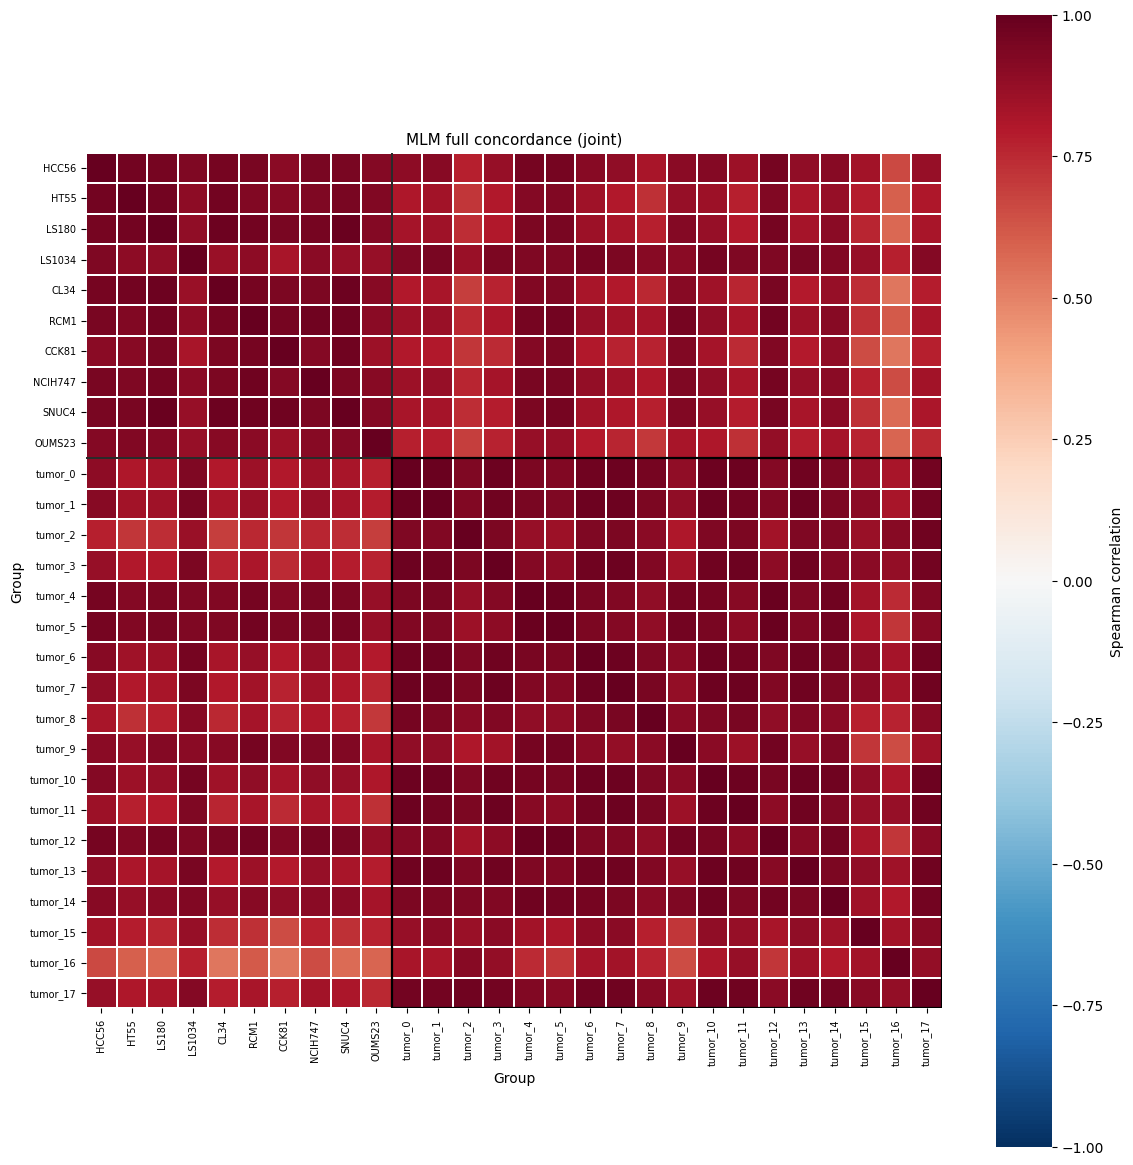

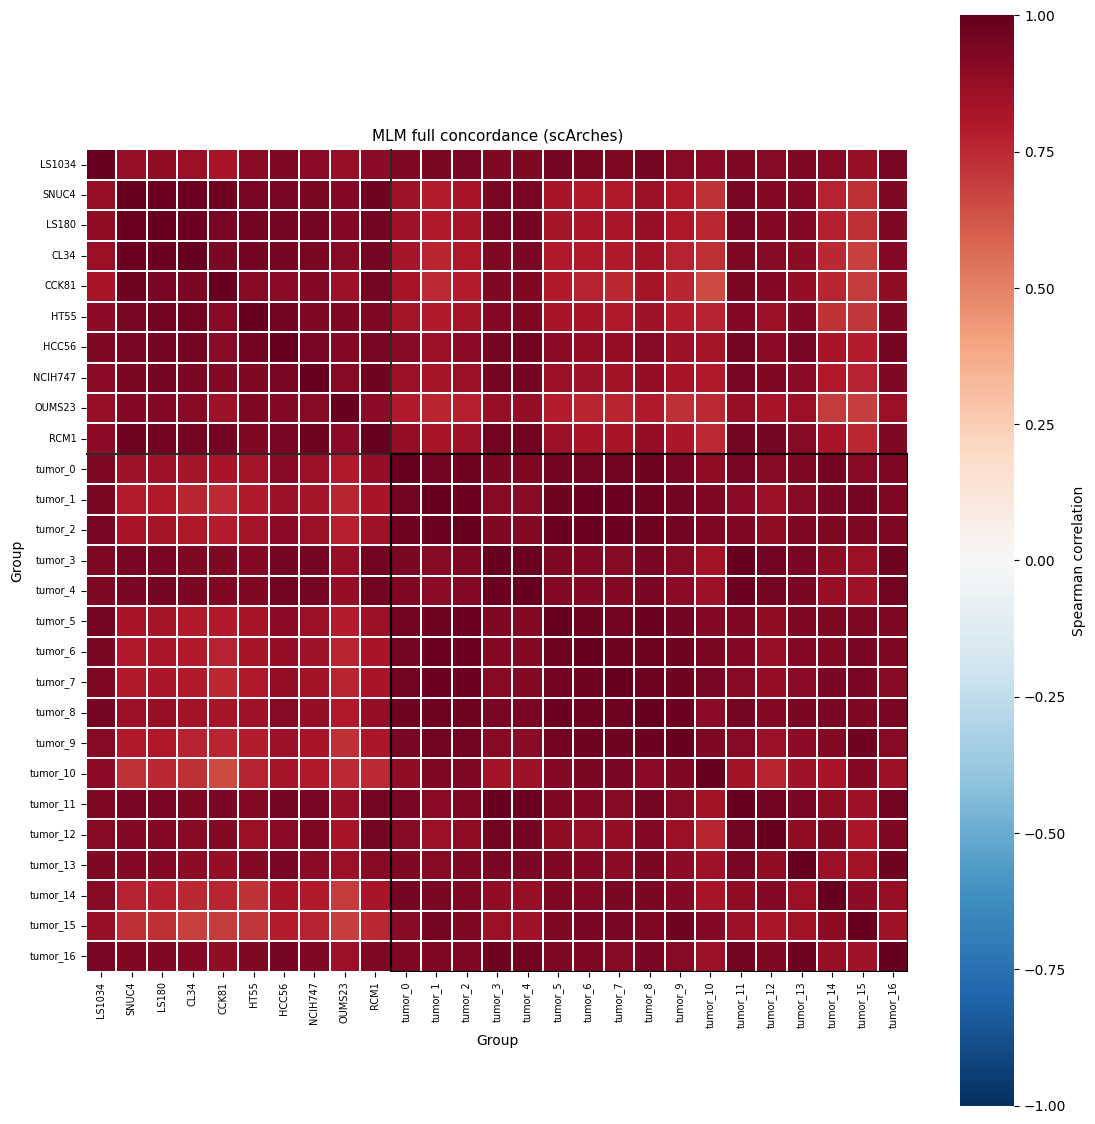

In [4]:
scores, score_obs, _ = mlm.load_scores(mlm_path)

joint_profiles = concordance.group_profiles(
    scores, joint_groups.loc[scores.index].astype(str), scores.index
)
arches_profiles = concordance.group_profiles(
    scores, arches_groups.loc[scores.index].astype(str), scores.index
)

joint_line_names = [str(line).replace("line_", "") for line in joint_line_order]
arches_line_names = [str(line).replace("line_", "") for line in arches_line_order]
joint_order = joint_line_names + list(tumor_order)
arches_tumor_order = sorted(
    [group for group in arches_profiles.index if str(group).startswith("tumor_")],
    key=matching.tumor_group_sort_key,
)
arches_order = arches_line_names + arches_tumor_order

joint_matrix = concordance.full_concordance(joint_profiles, joint_order)
arches_matrix = concordance.full_concordance(arches_profiles, arches_order)

plots.plot_full_concordance(
    joint_matrix,
    joint_line_names,
    list(tumor_order),
    FIG_DIR / "full_mlm_joint.png",
    "MLM full concordance (joint)",
)
plt.show()
plots.plot_full_concordance(
    arches_matrix,
    arches_line_names,
    arches_tumor_order,
    FIG_DIR / "full_mlm_arches.png",
    "MLM full concordance (scArches)",
)
plt.show()

## Pathway z-scored MLM concordance

Standardizing each pathway across groups removes the shared baseline
activity scale before correlating group profiles.

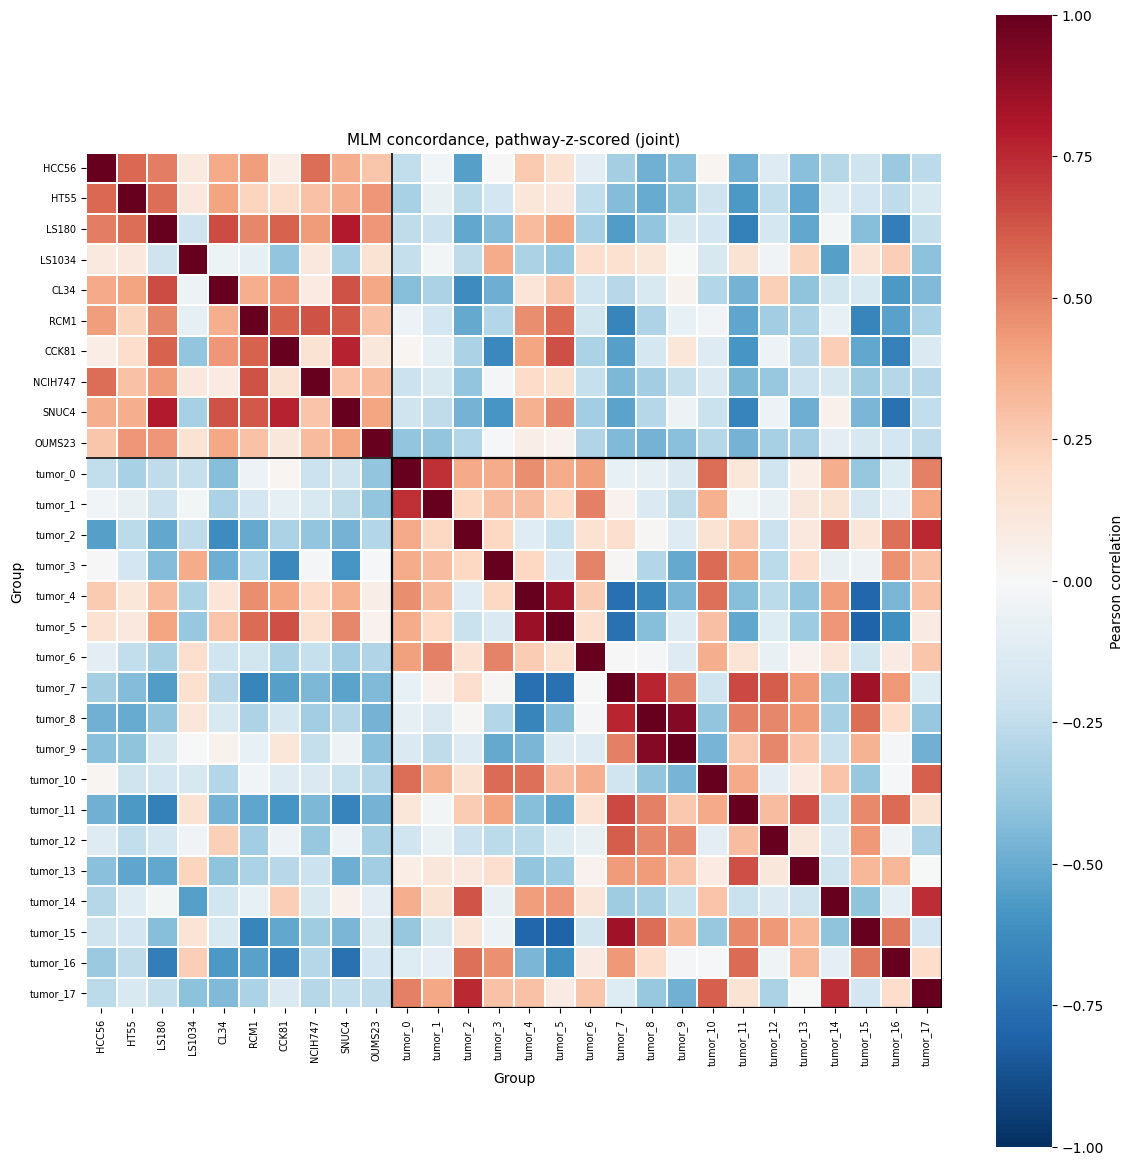

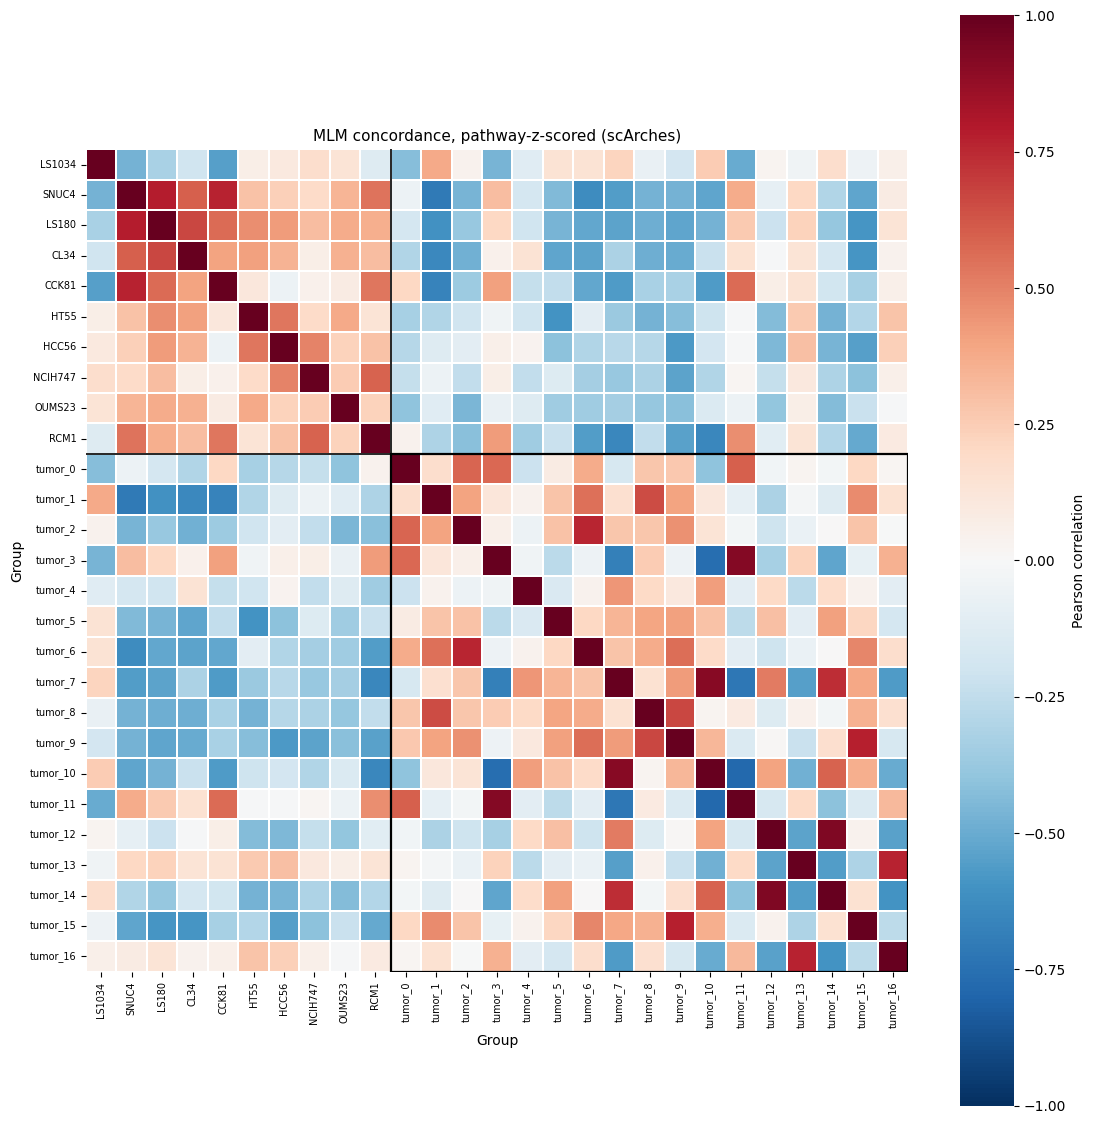

In [5]:
joint_z = concordance.zscored_concordance(joint_profiles, joint_order)
arches_z = concordance.zscored_concordance(arches_profiles, arches_order)

plots.plot_full_concordance(
    joint_z,
    joint_line_names,
    list(tumor_order),
    FIG_DIR / "full_mlm_z_joint.png",
    "MLM concordance, pathway-z-scored (joint)",
    cbar_label="Pearson correlation",
)
plt.show()
plots.plot_full_concordance(
    arches_z,
    arches_line_names,
    arches_tumor_order,
    FIG_DIR / "full_mlm_z_arches.png",
    "MLM concordance, pathway-z-scored (scArches)",
    cbar_label="Pearson correlation",
)
plt.show()

## Size-matched latent distance and kNN enrichment

Subsampling `n=80` cells per group equalizes group sizes for the symmetric
nearest-neighbor distance matrix; the `log2(observed / expected)` kNN matrix
shows all-vs-all neighborhood enrichment across the full dataset.

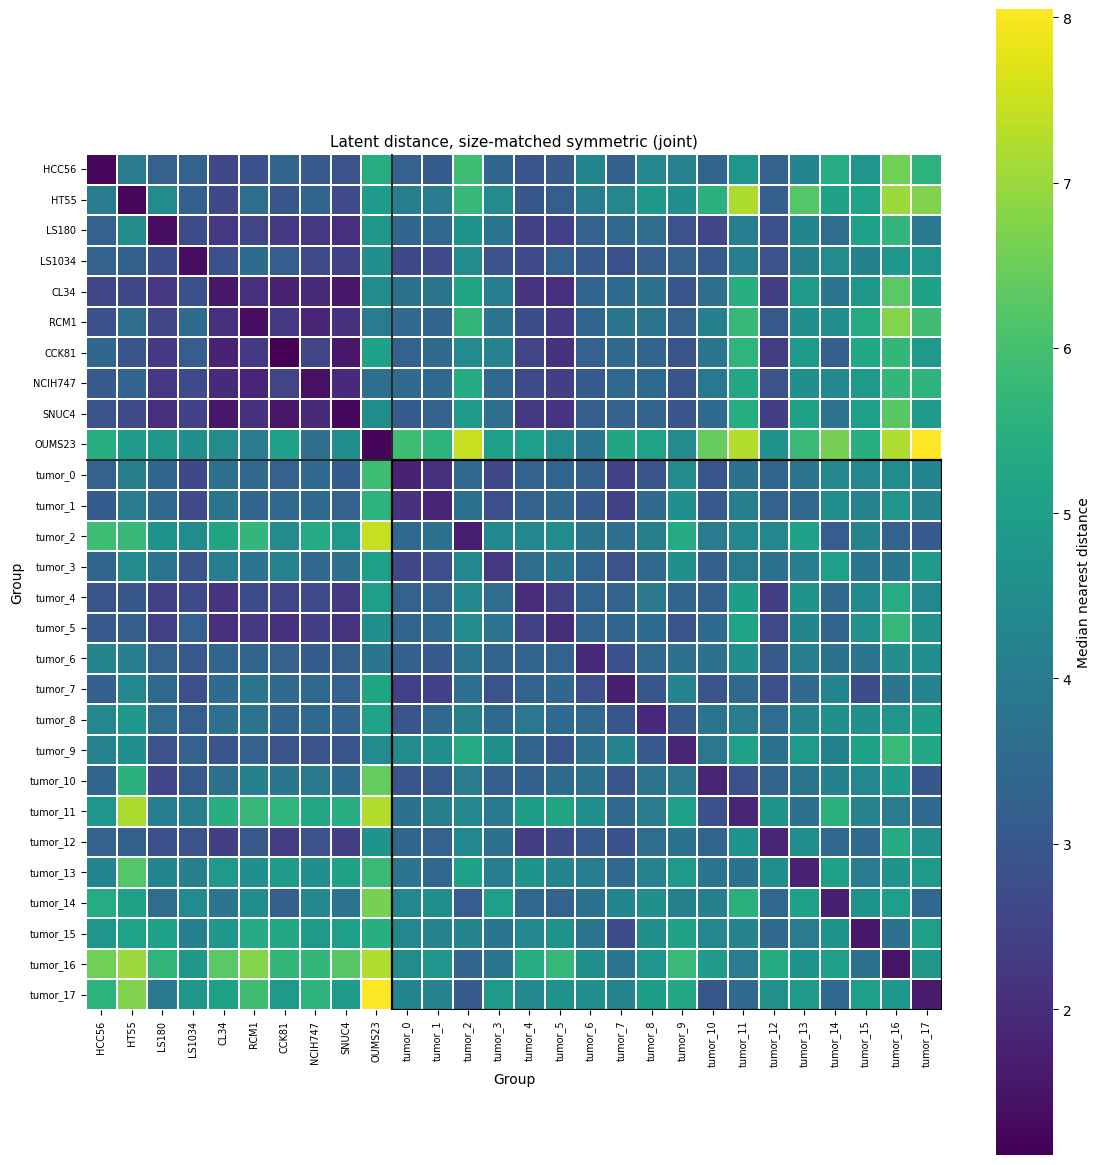

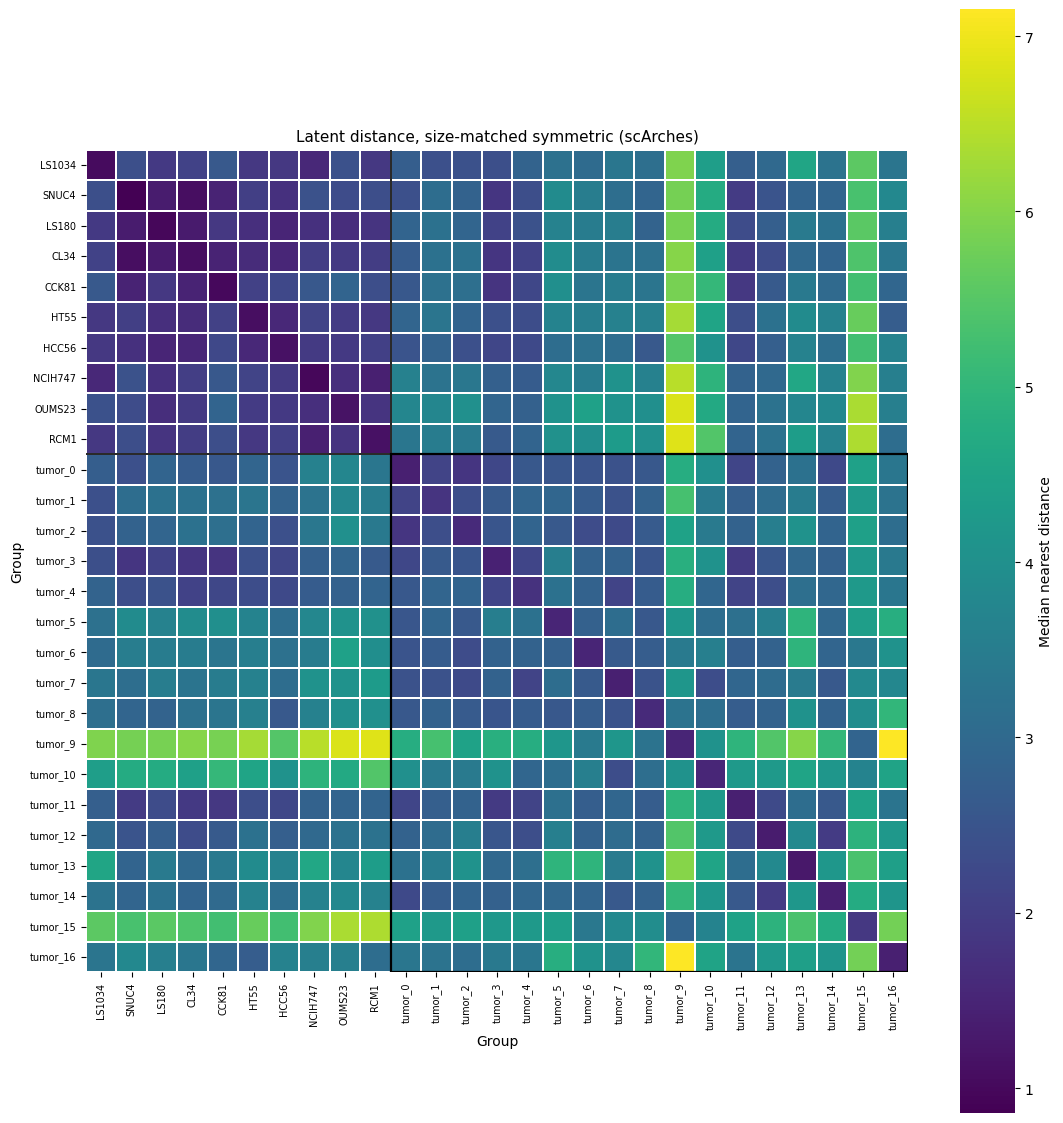

In [6]:
labels_joint = concordance.bare_group_labels(joint_groups)
labels_arches = concordance.bare_group_labels(arches_groups)

dist_joint = concordance.symmetric_nn_distance(
    joint.obsm["X_latent"], labels_joint, joint_order, n=SUBSAMPLE_N
)
dist_arches = concordance.symmetric_nn_distance(
    arches.obsm["X_latent_scarches"], labels_arches, arches_order, n=SUBSAMPLE_N
)

plots.plot_full_concordance(
    dist_joint,
    joint_line_names,
    list(tumor_order),
    FIG_DIR / "full_latent_distance_joint.png",
    "Latent distance, size-matched symmetric (joint)",
    cmap="viridis",
    center=None,
    vmin=None,
    vmax=None,
    cbar_label="Median nearest distance",
)
plt.show()
plots.plot_full_concordance(
    dist_arches,
    arches_line_names,
    arches_tumor_order,
    FIG_DIR / "full_latent_distance_arches.png",
    "Latent distance, size-matched symmetric (scArches)",
    cmap="viridis",
    center=None,
    vmin=None,
    vmax=None,
    cbar_label="Median nearest distance",
)
plt.show()

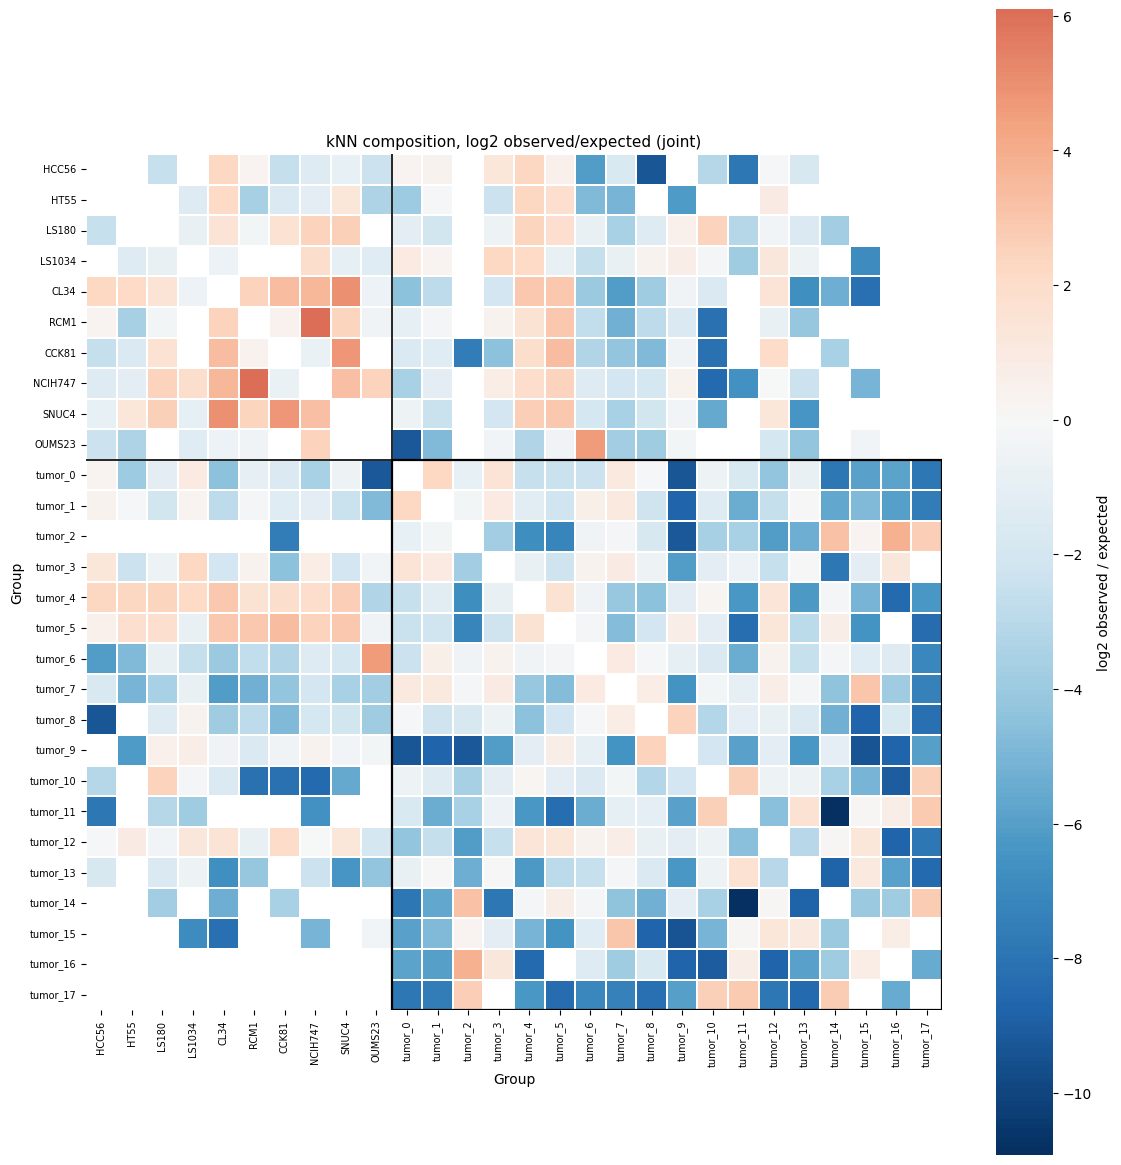

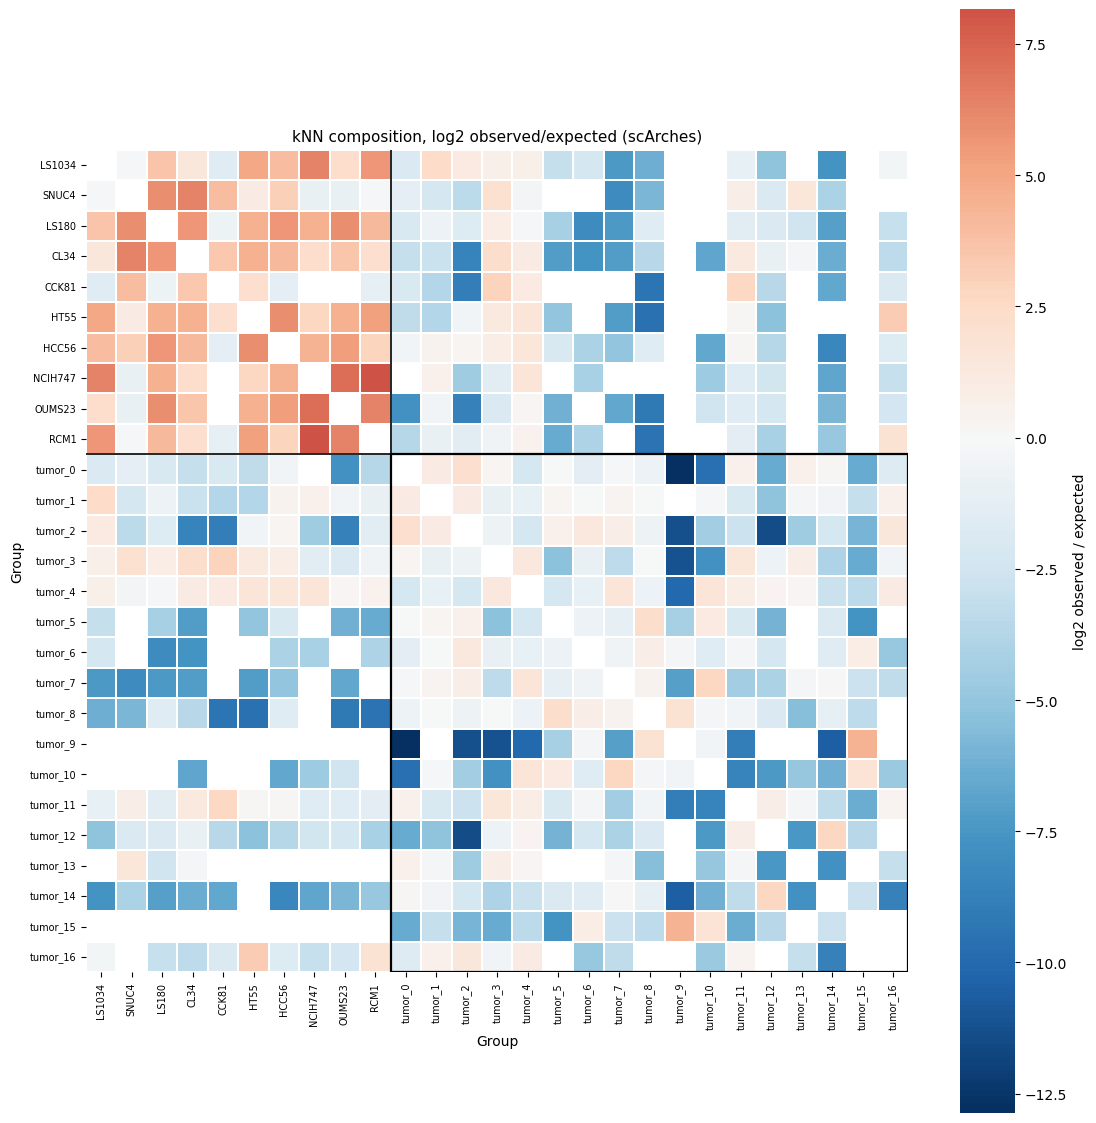

In [7]:
oe_joint = concordance.all_vs_all_knn_oe(
    joint.obsm["X_latent"], labels_joint, joint_order, k=K_MATCHING
)
oe_arches = concordance.all_vs_all_knn_oe(
    arches.obsm["X_latent_scarches"], labels_arches, arches_order, k=K_MATCHING
)

plots.plot_full_concordance(
    oe_joint,
    joint_line_names,
    list(tumor_order),
    FIG_DIR / "full_knn_oe_joint.png",
    "kNN composition, log2 observed/expected (joint)",
    cmap="RdBu_r",
    center=0,
    vmin=None,
    vmax=None,
    cbar_label="log2 observed / expected",
)
plt.show()
plots.plot_full_concordance(
    oe_arches,
    arches_line_names,
    arches_tumor_order,
    FIG_DIR / "full_knn_oe_arches.png",
    "kNN composition, log2 observed/expected (scArches)",
    cmap="RdBu_r",
    center=0,
    vmin=None,
    vmax=None,
    cbar_label="log2 observed / expected",
)
plt.show()

## Block summary

The block summary compares the mean and minimum correlation in the three
regions of the matrix (`cell line`, `cell line-tumor`, and `tumor`). It is
the only table saved from this notebook.

In [8]:
block_table = pd.DataFrame(
    {
        "MLM joint": concordance.block_summary(
            joint_matrix, joint_line_names, list(tumor_order)
        ),
        "MLM scArches": concordance.block_summary(
            arches_matrix, arches_line_names, arches_tumor_order
        ),
        "MLM z-scored joint": concordance.block_summary(
            joint_z, joint_line_names, list(tumor_order)
        ),
        "MLM z-scored scArches": concordance.block_summary(
            arches_z, arches_line_names, arches_tumor_order
        ),
    }
)
block_table.to_csv(OUT_DIR / "block_summary.csv")
block_table

,MLM joint,MLM scArches,MLM z-scored joint,MLM z-scored scArches
cell line mean,0.930,0.930,0.321,0.259
cell line-tumor mean,0.836,0.854,-0.218,-0.209
tumor mean,0.916,0.927,0.095,0.093
cell line min,0.823,0.823,-0.396,-0.550
cell line-tumor min,0.532,0.649,-0.743,-0.705
tumor min,0.649,0.763,-0.812,-0.783
